# Fresh vs Rotten Fruit Classification Using OpenCV

Image-Based Machine Learning Project
Domain: Computer Vision and Machine Learning

Image Processing: OpenCV

Machine Learning Algorithms:
- K-Nearest Neighbors (KNN)
- Decision Tree Classifier

Problem Type: Binary Image Classification

## 1. Introduction

Image classification is a computer vision technique that enables computers to identify and categorize objects from digital images.

In real-world applications, image classification is used in agriculture, healthcare, manufacturing, retail, and quality inspection.

In this project, we develop an image classification system to identify whether a fruit is fresh or rotten by analyzing its visual characteristics.

OpenCV is used to read, resize, and preprocess the images. The processed images are converted into numerical features, which are then provided to machine learning algorithms for classification.

We implement two supervised machine learning algorithms, K-Nearest Neighbors and Decision Tree, and compare their performance on the fruit image dataset.

## 2. Problem Statement
Manual identification of fresh and rotten fruits can be time-consuming, particularly when handling large quantities of fruits.

The objective of this project is to develop an automated image classification system that predicts whether a given fruit image belongs to the Fresh or Rotten category.

The system learns visual patterns from labeled fruit images and uses those patterns to classify new images.


## 3. Project Objectives

1. Understand and explore the fruit image dataset.
2. Load the provided training and testing images.
3. Preprocess images consistently using OpenCV.
4. Convert images into numerical features for machine learning.
5. Create a validation split from the training data.
6. Train KNN and Decision Tree classifiers.
7. Select the final model using validation performance only.
8. Compare both algorithms on the untouched test set.
9. Evaluate Fresh and Rotten predictions using class-wise metrics.
10. Save and load only the selected best model.
11. Demonstrate prediction on a new, unseen fruit image.

**Important:** The supplied dataset already contains separate training and testing folders. The test folder is kept out of model selection and is used only for final evaluation.


## 4. Dataset Understanding
We use the Fruits Fresh and Rotten for Classification dataset.

Dataset source: Kaggle – Fruits Fresh and Rotten for Classification

The dataset contains images of apples, bananas, and oranges in fresh and rotten conditions.

### 4.1 Original Dataset Categories
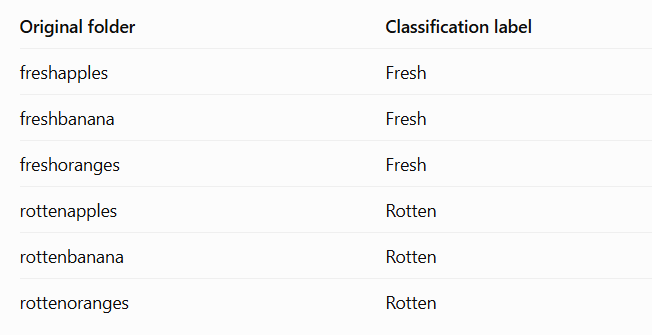

### 4.2 Dataset Directory Structure
Our dataset is organized into separate training and testing directories.

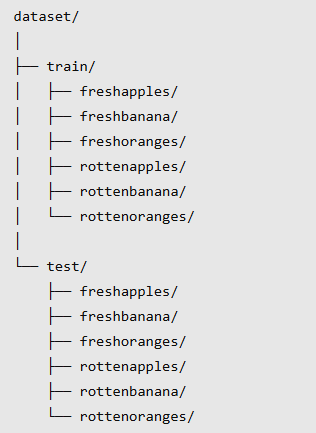

### 4.3 Target Label Encoding
We combine the six original categories into two target classes:
- 0 – Fresh
- 1 – Rotten

This converts the original dataset into a binary classification problem.

## 5. Importing Required Libraries
We import libraries based on their purpose as they are needed throughout the project.

The first set of libraries is used for image processing, numerical operations, dataset handling, and visualization.

In [1]:
import os
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 6. Defining Dataset Paths
We define the locations of the training and testing directories.

The training directory contains the images used to teach the machine learning algorithms.

The testing directory contains separate images used to evaluate how well the trained models perform on unseen examples.

In [2]:
# Main dataset directory

DATASET_DIR = Path("dataset")

# Training and testing directories

TRAIN_DIR = DATASET_DIR / "train"
TEST_DIR = DATASET_DIR / "test"

# Check whether both directories exist

print("Training Directory Exists:", TRAIN_DIR.exists())

print("Testing Directory Exists:", TEST_DIR.exists())

Training Directory Exists: True
Testing Directory Exists: True


### 6.1 Inspecting Dataset Categories
Before loading the images, we inspect the folder names in both directories.

This confirms that all six original fruit categories are available.

In [3]:
print("Training Categories:")

for folder in sorted(TRAIN_DIR.iterdir()):
    if folder.is_dir():
        print(folder.name)


print("\nTesting Categories:")

for folder in sorted(TEST_DIR.iterdir()):
    if folder.is_dir():
        print(folder.name)

Training Categories:
.ipynb_checkpoints
freshapples
freshbanana
freshoranges
rottenapples
rottenbanana
rottenoranges

Testing Categories:
.ipynb_checkpoints
freshapples
freshbanana
freshoranges
rottenapples
rottenbanana
rottenoranges


## 7. Loading and Labeling Images
In this step, we load the images from the training and testing directories.

Each image is associated with a numerical label based on its original folder name.
Labeling logic
- Folder names beginning with fresh receive label 0.
- Folder names beginning with rotten receive label 1.

We create a reusable function to avoid repeating the same image-loading operations for the training and testing datasets.

The function stores:
- Image file paths.
- Corresponding numerical labels.
- Original category names.

In [4]:
# Supported image formats

IMAGE_EXTENSIONS = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
)


# Function to load image paths and labels

def collect_image_paths(directory):

    image_paths = []
    labels = []
    categories = []

    for class_folder in sorted(directory.iterdir()):

        if not class_folder.is_dir():
            continue

        folder_name = class_folder.name.lower()

        if folder_name.startswith("fresh"):

            label = 0
            category = "Fresh"

        elif folder_name.startswith("rotten"):

            label = 1
            category = "Rotten"

        else:

            continue

        for image_path in class_folder.rglob("*"):

            if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:

                image_paths.append(str(image_path))

                labels.append(label)

                categories.append(category)

    return image_paths, labels, categories

### 7.1 Collecting Training and Testing Image Information
We call the function separately for the training and testing directories.

This ensures that the images remain separated throughout the project.

In [5]:
# Collect training image information

train_paths, train_labels, train_categories = collect_image_paths(
    TRAIN_DIR
)


# Collect testing image information

test_paths, test_labels, test_categories = collect_image_paths(
    TEST_DIR
)


print("Total Training Images:", len(train_paths))

print("Total Testing Images:", len(test_paths))

Total Training Images: 10901
Total Testing Images: 2698


### 7.2 Creating Dataset DataFrames
We organize the collected image information into Pandas DataFrames.

Each record contains the image path, numerical label, and readable category.

This makes the dataset easier to inspect and analyze.

In [6]:
# Training DataFrame

train_df = pd.DataFrame({

    "Image_Path": train_paths,

    "Label": train_labels,

    "Category": train_categories

})


# Testing DataFrame

test_df = pd.DataFrame({

    "Image_Path": test_paths,

    "Label": test_labels,

    "Category": test_categories

})


print("Training Dataset:")

display(train_df.head())


print("\nTesting Dataset:")

display(test_df.head())

Training Dataset:


,Image_Path,Label,Category
0,dataset\train\freshapples\rotated_by_15_Screen...,0,Fresh
1,dataset\train\freshapples\rotated_by_15_Screen...,0,Fresh
2,dataset\train\freshapples\rotated_by_15_Screen...,0,Fresh
3,dataset\train\freshapples\rotated_by_15_Screen...,0,Fresh
4,dataset\train\freshapples\rotated_by_15_Screen...,0,Fresh



Testing Dataset:


,Image_Path,Label,Category
0,dataset\test\freshapples\rotated_by_15_Screen ...,0,Fresh
1,dataset\test\freshapples\rotated_by_15_Screen ...,0,Fresh
2,dataset\test\freshapples\rotated_by_15_Screen ...,0,Fresh
3,dataset\test\freshapples\rotated_by_15_Screen ...,0,Fresh
4,dataset\test\freshapples\rotated_by_15_Screen ...,0,Fresh


## 8. Dataset Exploration
Exploratory Data Analysis helps us understand the structure and distribution of the dataset before applying image preprocessing.

We examine the number of images available in each class and verify whether both Fresh and Rotten categories are represented.
### 8.1 Dataset Information
We check:
- Total number of training images.
- Total number of testing images.
- Missing image paths.
- Class distribution.

In [7]:
print("Training Dataset Shape:", train_df.shape)

Training Dataset Shape: (10901, 3)


In [8]:
print("Testing Dataset Shape:", test_df.shape)

Testing Dataset Shape: (2698, 3)


In [9]:
print("\nTraining Class Distribution:")

print(train_df["Category"].value_counts())


Training Class Distribution:
Category
Rotten    6161
Fresh     4740
Name: count, dtype: int64


In [10]:
print("\nTesting Class Distribution:")

print(test_df["Category"].value_counts())


Testing Class Distribution:
Category
Rotten    1534
Fresh     1164
Name: count, dtype: int64


In [11]:
print("\nMissing Values in Training Dataset:")

print(train_df.isnull().sum())


Missing Values in Training Dataset:
Image_Path    0
Label         0
Category      0
dtype: int64


In [12]:
print("\nMissing Values in Testing Dataset:")

print(test_df.isnull().sum())


Missing Values in Testing Dataset:
Image_Path    0
Label         0
Category      0
dtype: int64


### 8.2 Visualizing Class Distribution
We visualize the number of Fresh and Rotten images in the training and testing datasets.

A balanced class distribution can help prevent the model from favoring one category simply because it contains more images.

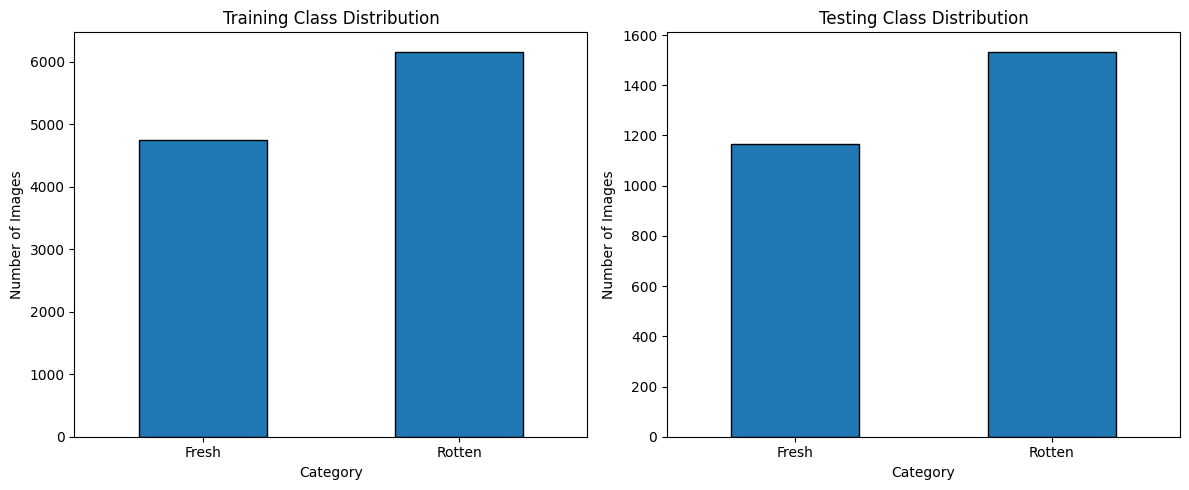

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))


# Training class distribution

train_df["Category"].value_counts().reindex(
    ["Fresh", "Rotten"], fill_value=0
).plot(
    kind="bar",
    ax=axes[0],
    edgecolor="black"
)

axes[0].set_title("Training Class Distribution")

axes[0].set_xlabel("Category")

axes[0].set_ylabel("Number of Images")

axes[0].tick_params(axis="x", rotation=0)


# Testing class distribution

test_df["Category"].value_counts().reindex(
    ["Fresh", "Rotten"], fill_value=0
).plot(
    kind="bar",
    ax=axes[1],
    edgecolor="black"
)

axes[1].set_title("Testing Class Distribution")

axes[1].set_xlabel("Category")

axes[1].set_ylabel("Number of Images")

axes[1].tick_params(axis="x", rotation=0)


plt.tight_layout()

plt.show()

## 9. Visualizing Sample Fruit Images
Before preprocessing, we visualize a few images from the dataset.

This helps us understand the appearance of different fruits and observe possible visual differences between fresh and rotten fruits.

We display sample images from both categories.

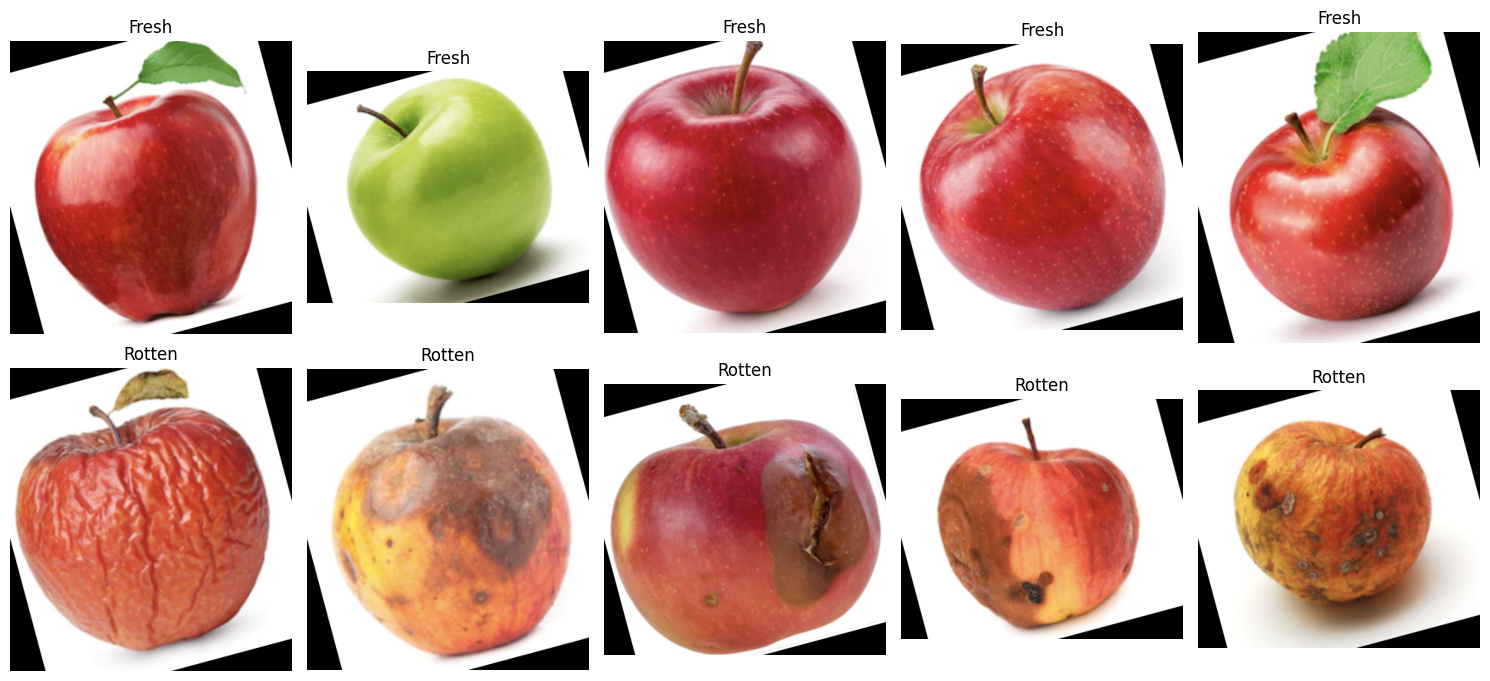

In [14]:
# Select sample images from both categories

fresh_samples = train_df[
    train_df["Label"] == 0
].head(5)


rotten_samples = train_df[
    train_df["Label"] == 1
].head(5)


sample_df = pd.concat([
    fresh_samples,
    rotten_samples
])


plt.figure(figsize=(15, 7))


for i, (_, row) in enumerate(sample_df.iterrows()):

    image = cv2.imread(row["Image_Path"])

    if image is None:
        continue

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    plt.subplot(2, 5, i + 1)

    plt.imshow(image)

    plt.title(row["Category"])

    plt.axis("off")


plt.tight_layout()

plt.show()

## 10. Image Preprocessing Using OpenCV
Image preprocessing is an essential step in computer vision.

Images may have different dimensions, color formats, and pixel intensity values. These variations must be handled before converting images into numerical features.

We perform the following preprocessing operations:
### 10.1 Image Reading
The cv2.imread() function loads an image from its file path.
### 10.2 Image Resizing
We resize all images to 32 × 32 pixels.

This ensures that every image has identical dimensions.
### 10.3 Color Space Conversion
OpenCV reads images in BGR format by default.

We convert BGR images into RGB format using cv2.cvtColor().
### 10.4 Pixel Normalization
Image pixel values generally range from 0 to 255.

We divide each pixel value by 255 to scale the values between 0 and 1.

This creates a consistent numerical range for the machine learning algorithms.

In [15]:

# Define image dimensions
IMG_SIZE = 32

# Shared preprocessing function for training, testing and new images
def preprocess_image(image_path):

    # Read image in OpenCV's BGR format
    image = cv2.imread(str(image_path))

    if image is None:
        return None

    # Resize to the same dimensions for every image
    image = cv2.resize(
        image,
        (IMG_SIZE, IMG_SIZE),
        interpolation=cv2.INTER_AREA
    )

    # Convert BGR to RGB
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Normalize pixel values to the range 0 to 1
    image = image.astype(np.float32) / 255.0

    return image


### 10.1 Processing Training Images
We apply the preprocessing function to every training image.

The processed images are stored in a NumPy array.

Images that cannot be read are skipped, and their corresponding labels are also excluded.

In [16]:
X_train_images = []

y_train = []

for image_path, label in zip(train_paths, train_labels):

    image = preprocess_image(image_path)

    if image is not None:

        X_train_images.append(image)

        y_train.append(label)


X_train_images = np.array(X_train_images)

y_train = np.array(y_train)


print("Training Images Shape:", X_train_images.shape)

print("Training Labels Shape:", y_train.shape)

Training Images Shape: (10901, 32, 32, 3)
Training Labels Shape: (10901,)


### 10.2 Processing Testing Images
We apply the exact same preprocessing operations to the testing images.

It is important that training and testing images undergo identical preprocessing so that the models receive features in the same format.

The testing images are not used during model training.

In [ ]:
X_test_images = []

y_test = []

for image_path, label in zip(test_paths, test_labels):

    image = preprocess_image(image_path)

    if image is not None:

        X_test_images.append(image)

        y_test.append(label)


X_test_images = np.array(X_test_images)

y_test = np.array(y_test)


print("Testing Images Shape:", X_test_images.shape)

print("Testing Labels Shape:", y_test.shape)

### 10.3 Verifying Processed Images
We visualize the processed images to verify that resizing, color conversion, and normalization have been applied successfully.

All images should have the same dimensions.

In [ ]:
plt.figure(figsize=(12, 6))


for i in range(min(8, len(X_train_images))):

    plt.subplot(2, 4, i + 1)

    plt.imshow(X_train_images[i])

    category = "Fresh" if y_train[i] == 0 else "Rotten"

    plt.title(category)

    plt.axis("off")


plt.tight_layout()

plt.show()

## 11. Feature Extraction
Machine learning algorithms require numerical input.

Although images contain visual information, the algorithms used in this project cannot directly interpret images in their original visual form.

Therefore, we convert each preprocessed image into a numerical feature vector.
Pixel-Based Feature Extraction
We use the pixel intensity values of each RGB image as features.

Each image has:
- Height = 32 pixels
- Width = 32 pixels
- Color channels = 3 (RGB)

Total number of features:

32 * 32 * 3 = 3072


Therefore, each image is represented by a one-dimensional array containing 3,072 numerical features.

In [ ]:

# Flatten the preprocessed images into numerical feature vectors
X_train_all = X_train_images.reshape(
    X_train_images.shape[0],
    -1
)

X_test = X_test_images.reshape(
    X_test_images.shape[0],
    -1
)

# Keep the original training labels before creating the validation split
y_train_all = y_train.copy()

# Split ONLY the training data into model-training and validation subsets
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_all,
    y_train_all,
    test_size=0.20,
    random_state=42,
    stratify=y_train_all
)

print("Model Training Features:", X_fit.shape)
print("Validation Features:", X_val.shape)
print("Final Test Features:", X_test.shape)

print("\nModel Training Labels:", y_fit.shape)
print("Validation Labels:", y_val.shape)
print("Final Test Labels:", y_test.shape)



## 12. Preparing Input Features and Target Labels

Each 32 × 32 RGB image is flattened into a vector containing 3,072 pixel values.

The original training folder is divided into:
- **Training subset (80%)** – used to fit the algorithms.
- **Validation subset (20%)** – used to compare configurations and select the final model.

The provided test folder remains separate and is not used to choose model settings. This helps prevent test-set information from influencing model selection.


In [ ]:
# Display Training Input Features

print("Training Input Features:", X_fit.shape)

print("Training Target Labels:", y_fit.shape)


# Display Validation Input Features

print("\nValidation Input Features:", X_val.shape)

print("Validation Target Labels:", y_val.shape)


# Display Testing Input Features

print("\nTesting Input Features:", X_test.shape)

print("Testing Target Labels:", y_test.shape)


# Display Unique Labels

print("\nUnique Training Labels:", np.unique(y_fit))

print("Unique Validation Labels:", np.unique(y_val))

print("Unique Testing Labels:", np.unique(y_test))

## 13. Model Building and Training
In supervised machine learning, a model learns patterns from labeled training data and uses those patterns to predict the categories of new data.

For this project, we implement two classification algorithms:
1. K-Nearest Neighbors (KNN)
2. Decision Tree Classifier

Both models are trained using the same training dataset so that their performance can be compared fairly.

### 13.1 K-Nearest Neighbors (KNN)
K-Nearest Neighbors is a supervised machine learning algorithm used for classification and regression.

It predicts the category of a new data point by identifying the K closest data points in the training dataset.

The majority class among those nearest neighbors becomes the predicted category.

Working principle:
1. Select the value of K.
2. Calculate the distance between the new image and training images.
3. Identify the K nearest neighbors.
4. Count the categories of the selected neighbors.
5. Assign the majority category as the prediction.
   
Configuration:
- Number of neighbors: 5
- Distance metric: Euclidean
- Algorithm: Auto

In [ ]:

from sklearn.neighbors import KNeighborsClassifier

# Initialize KNN
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    metric="euclidean",
    algorithm="auto"
)

# Train KNN only on the training subset
knn_model.fit(X_fit, y_fit)

print("KNN Model Training Completed Successfully.")


### 13.2 Decision Tree Classifier
A Decision Tree is a supervised machine learning algorithm that makes predictions using a sequence of decision rules.

It divides the dataset into smaller groups based on feature values.

Each internal node represents a decision, and each leaf node represents the final predicted class.

Working principle:
1. Analyze the training features.
2. Identify feature-based splitting conditions.
3. Divide the data into smaller groups.
4. Continue splitting until the stopping conditions are reached.
5. Assign a predicted category at the leaf node.
We limit the maximum depth of the tree to control model complexity and reduce overfitting.

Configuration:
- Maximum depth: 20
- Random state: 42
- Criterion: Gini impurity (default)

In [ ]:

from sklearn.tree import DecisionTreeClassifier

# Use a regularized Decision Tree to reduce excessive complexity
dt_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=15,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42
)

# Train Decision Tree only on the training subset
dt_model.fit(X_fit, y_fit)

print("Decision Tree Model Training Completed Successfully.")
print("Tree Depth:", dt_model.get_depth())
print("Number of Leaves:", dt_model.get_n_leaves())



## 14. Generating Validation and Test Predictions

Both models first generate predictions for the validation subset. These validation results are used for model selection.

After the final model-selection rule is fixed, both algorithms are also evaluated on the separate test set for a fair comparison. The test results are reported, but they are not used to change the selected model.


In [ ]:

# Validation predictions: used for model selection
knn_val_predictions = knn_model.predict(X_val)
dt_val_predictions = dt_model.predict(X_val)

# Test predictions: reserved for final performance reporting
knn_predictions = knn_model.predict(X_test)
dt_predictions = dt_model.predict(X_test)

print("Validation and final test predictions generated.")


### 14.1 Comparing Actual and Predicted Categories
We compare the actual target labels with the predictions generated by both models.

The numerical labels are converted into readable category names to make the results easier to understand.

In [ ]:
# Convert numerical labels into category names

label_mapping = {
    0: "Fresh",
    1: "Rotten"
}


comparison_df = pd.DataFrame({

    "Actual": [
        label_mapping[label] for label in y_test
    ],

    "KNN_Predicted": [
        label_mapping[label] for label in knn_predictions
    ],

    "Decision_Tree_Predicted": [
        label_mapping[label] for label in dt_predictions
    ]

})


display(comparison_df.head(20))

## 15. Model Evaluation
Model evaluation measures how effectively a trained machine learning model predicts the correct categories.

We evaluate both algorithms using the testing dataset.

The following metrics are used:
### 15.1 Accuracy
Accuracy measures the proportion of correctly classified images out of the total number of testing images.
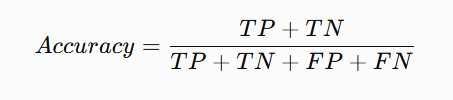

### 15.2 Precision
Precision measures how many images predicted as a particular category actually belong to that category.
### 15.3 Recall
Recall measures how many actual images belonging to a category are correctly identified.
### 15.4 F1-Score
F1-score is the harmonic mean of precision and recall.

It provides a combined measure of both metrics.

In [ ]:

from sklearn.metrics import accuracy_score

# Final test accuracy for reporting only
knn_accuracy = accuracy_score(y_test, knn_predictions)
dt_accuracy = accuracy_score(y_test, dt_predictions)

print("KNN Final Test Accuracy:", round(knn_accuracy * 100, 2), "%")
print("Decision Tree Final Test Accuracy:", round(dt_accuracy * 100, 2), "%")

print("\nThese test scores are reported after model selection.")
print("They are not used to choose or retune the final model.")


### 15.1 KNN Classification Report
The classification report provides precision, recall, F1-score, and support for each category.

This allows us to understand the performance of KNN separately for Fresh and Rotten fruits.

In [ ]:
from sklearn.metrics import classification_report


print("KNN Classification Report\n")


print(
    classification_report(
        y_test,
        knn_predictions,
        labels=[0, 1],
        target_names=["Fresh", "Rotten"],
        zero_division=0
    )
)

### 15.2 Decision Tree Classification Report
We generate the classification report for the Decision Tree model.

Comparing this report with the KNN report helps us understand which model performs better for each fruit category.

In [ ]:
print("Decision Tree Classification Report\n")


print(
    classification_report(
        y_test,
        dt_predictions,
        labels=[0, 1],
        target_names=["Fresh", "Rotten"],
        zero_division=0
    )
)

## 16. Confusion Matrix
A confusion matrix is a table used to evaluate classification performance by comparing actual categories with predicted categories.

For binary classification, it contains four outcomes:
- True Positive (TP): Rotten fruits correctly predicted as Rotten.
- True Negative (TN): Fresh fruits correctly predicted as Fresh.
- False Positive (FP): Fresh fruits incorrectly predicted as Rotten.
- False Negative (FN): Rotten fruits incorrectly predicted as Fresh.

The confusion matrix helps us understand the types of mistakes made by each model.

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


# Calculate KNN confusion matrix

knn_cm = confusion_matrix(
    y_test,
    knn_predictions,
    labels=[0, 1]
)


# Display KNN confusion matrix

knn_display = ConfusionMatrixDisplay(
    confusion_matrix=knn_cm,
    display_labels=["Fresh", "Rotten"]
)


knn_display.plot(cmap="Blues")

plt.title("KNN Confusion Matrix")

plt.show()

In [ ]:
# Calculate Decision Tree confusion matrix

dt_cm = confusion_matrix(
    y_test,
    dt_predictions,
    labels=[0, 1]
)


# Display Decision Tree confusion matrix

dt_display = ConfusionMatrixDisplay(
    confusion_matrix=dt_cm,
    display_labels=["Fresh", "Rotten"]
)


dt_display.plot(cmap="Greens")

plt.title("Decision Tree Confusion Matrix")

plt.show()

## 17. Model Performance Comparison
In this section, we compare the performance of KNN and Decision Tree.

Accuracy provides an overall measure of classification performance, while precision, recall, and F1-score provide additional information about individual classes.

We create a comparison table and visualize the accuracy scores using a bar chart.

In [ ]:
# Create model comparison DataFrame

model_comparison = pd.DataFrame({

    "Model": [
        "KNN",
        "Decision Tree"
    ],

    "Accuracy": [
        knn_accuracy,
        dt_accuracy
    ]

})


display(model_comparison)

In [ ]:
# Visualize model accuracy

plt.figure(figsize=(8, 5))


plt.bar(
    model_comparison["Model"],
    model_comparison["Accuracy"],
    edgecolor="black"
)


plt.title("KNN vs Decision Tree Accuracy")

plt.xlabel("Classification Algorithm")

plt.ylabel("Accuracy")

plt.ylim(0, 1)

plt.show()


### 17.1 Identifying the Best-Performing Model

The final model is selected using **validation accuracy**, with weighted F1-score as the tie-breaker.

The final test set is not used in this decision. This is important because repeatedly selecting models based on test results can make the reported test performance overly optimistic.


In [ ]:

from sklearn.metrics import f1_score, accuracy_score

# Calculate validation metrics for model selection
knn_val_accuracy = accuracy_score(y_val, knn_val_predictions)
dt_val_accuracy = accuracy_score(y_val, dt_val_predictions)

knn_val_f1 = f1_score(
    y_val, knn_val_predictions,
    average="weighted",
    zero_division=0
)

dt_val_f1 = f1_score(
    y_val, dt_val_predictions,
    average="weighted",
    zero_division=0
)

validation_comparison = pd.DataFrame({
    "Model": ["KNN", "Decision Tree"],
    "Validation Accuracy": [knn_val_accuracy, dt_val_accuracy],
    "Validation Weighted F1": [knn_val_f1, dt_val_f1]
})

display(validation_comparison.round(4))

# Select using validation accuracy, then weighted F1 as tie-breaker
if (knn_val_accuracy, knn_val_f1) >= (dt_val_accuracy, dt_val_f1):
    best_model = knn_model
    best_model_name = "KNN"
    best_validation_accuracy = knn_val_accuracy
    best_validation_f1 = knn_val_f1
else:
    best_model = dt_model
    best_model_name = "Decision Tree"
    best_validation_accuracy = dt_val_accuracy
    best_validation_f1 = dt_val_f1

print("Selected Best Model:", best_model_name)
print("Validation Accuracy:", round(best_validation_accuracy * 100, 2), "%")
print("Validation Weighted F1:", round(best_validation_f1, 4))



## 18. Prediction on New and Unseen Images

Only the selected model is used for the final prediction workflow.

The same `preprocess_image()` function is reused for new images, so resizing, color conversion and normalization stay consistent with training and testing.


In [ ]:

# Reuse the exact same preprocessing function for unseen images
def preprocess_new_image(image_path):

    image = preprocess_image(image_path)

    if image is None:
        raise ValueError(
            "Unable to read the image. Please check the file path."
        )

    # Flatten to the same feature shape used during model training
    return image.reshape(1, -1)


### 18.1 Loading a New Fruit Image
We provide the file path of a new fruit image.

The image is displayed before prediction to verify that the correct image has been selected.

In [ ]:
# Specify the path of a new fruit image

new_image_path = "my_unseen_fruit.jpg"


# Read image for visualization

new_image = cv2.imread(new_image_path)


if new_image is None:

    print("Image not found. Please check the image path.")

else:

    new_image_rgb = cv2.cvtColor(
        new_image,
        cv2.COLOR_BGR2RGB
    )


    plt.figure(figsize=(5, 5))

    plt.imshow(new_image_rgb)

    plt.title("New Fruit Image")

    plt.axis("off")

    plt.show()

### 18.2 Predicting the Fruit Category
After loading the new image, we apply the same preprocessing and feature extraction operations.

Only the selected best-performing model generates the final prediction for the unseen fruit image.

We compare their outputs to understand how they classify the unseen image.

In [ ]:

if new_image is not None:

    new_image_features = preprocess_new_image(new_image_path)

    # Predict using only the selected model
    final_prediction = best_model.predict(new_image_features)[0]

    label_mapping = {
        0: "Fresh",
        1: "Rotten"
    }

    predicted_category = label_mapping[int(final_prediction)]

    print("Model Used:", best_model_name)
    print("Predicted Fruit Category:", predicted_category)

    if hasattr(best_model, "predict_proba"):
        probabilities = best_model.predict_proba(new_image_features)[0]
        class_probabilities = {
            label_mapping[int(class_label)]: round(float(probability) * 100, 2)
            for class_label, probability in zip(best_model.classes_, probabilities)
        }
        print("Class Probabilities:", class_probabilities)



## 19. Saving the Best Model

After model selection using validation data, only the selected classifier is saved. The comparison models are not saved as separate model files.


In [ ]:

import joblib

# Save only the selected model
joblib.dump(
    best_model,
    "best_fruit_classifier.pkl"
)

# Save the selected model name for reference
joblib.dump(
    best_model_name,
    "best_fruit_classifier_name.pkl"
)

print("Selected model saved successfully.")
print("Saved Model:", best_model_name)
print("Model File: best_fruit_classifier.pkl")


### 19.1 Loading the Saved Best Model

We load the single saved best-performing model.

The loaded model can now be used for predictions without training KNN and Decision Tree again.

In [ ]:

# Load only the selected model
loaded_best_model = joblib.load(
    "best_fruit_classifier.pkl"
)

loaded_model_name = joblib.load(
    "best_fruit_classifier_name.pkl"
)

print("Best model loaded successfully.")
print("Loaded Model:", loaded_model_name)

# Verify the loaded model on the same unseen image
if new_image is not None:

    loaded_prediction = loaded_best_model.predict(
        new_image_features
    )[0]

    label_mapping = {
        0: "Fresh",
        1: "Rotten"
    }

    print(
        "Prediction from Loaded Model:",
        label_mapping[int(loaded_prediction)]
    )



## 20. Final Evaluation of the Selected Model

The selected model is evaluated on the untouched test set. Review class-wise precision, recall and F1-score, not accuracy alone. In particular, Rotten recall measures how many actual rotten fruit images are correctly identified.


In [ ]:

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Generate final predictions from the selected model on the test set
final_test_predictions = loaded_best_model.predict(X_test)

print("Selected Model:", loaded_model_name)
print("\nFinal Test Classification Report:")
print(
    classification_report(
        y_test,
        final_test_predictions,
        labels=[0, 1],
        target_names=["Fresh", "Rotten"],
        zero_division=0
    )
)

print("Final Test Accuracy:",
      round(accuracy_score(y_test, final_test_predictions) * 100, 2), "%")


In [ ]:

# Display confusion matrix for the selected model
final_cm = confusion_matrix(
    y_test,
    final_test_predictions,
    labels=[0, 1]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=["Fresh", "Rotten"]
)

display.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix - {loaded_model_name}")
plt.show()


In [ ]:
import joblib

joblib.dump(best_model, "best_fruit_classifier.pkl")

print("Selected model saved successfully!")

In [ ]:
loaded_model = joblib.load("best_fruit_classifier.pkl")

print("Saved model loaded successfully!")

In [ ]:
# Import OpenCV and NumPy
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load a new fruit image
image_path = "my_unseen_fruit.jpg"

# Preprocess the image using the existing preprocessing function
new_image = preprocess_image(image_path)

# Reshape the image for prediction
new_image = new_image.reshape(1, -1)

# Predict using the loaded model
prediction = loaded_model.predict(new_image)[0]

# Convert numerical prediction into class name
class_names = {
    0: "Fresh",
    1: "Rotten"
}

predicted_class = class_names[prediction]

# Display prediction
print("Predicted Class:", predicted_class)

# Display probability if supported by the model
if hasattr(loaded_model, "predict_proba"):
    probabilities = loaded_model.predict_proba(new_image)[0]

    for class_label, probability in zip(
        loaded_model.classes_, probabilities
    ):
        print(
            f"{class_names[class_label]}: {probability * 100:.2f}%"
        )

In [ ]:

# ============================================================
# FRESH VS ROTTEN FRUIT CLASSIFICATION
# Deployment using Gradio
# ============================================================

# 1. Import Required Libraries
import gradio as gr
import cv2
import numpy as np
import joblib

# 2. Load the Saved Model
model = joblib.load("best_fruit_classifier.pkl")

print("Model loaded successfully!")

# 3. Define Class Labels
class_names = {
    0: "Fresh",
    1: "Rotten"
}

# 4. Define Prediction Function
def predict_fruit(image):

    # Check whether an image was uploaded
    if image is None:
        return {"No image uploaded": 1.0}

    # Gradio provides the image in RGB format
    # Resize image to match training dimensions
    processed_image = cv2.resize(image, (32, 32))

    # Normalize pixel values
    processed_image = processed_image.astype("float32") / 255.0

    # Flatten image for model input
    processed_image = processed_image.flatten().reshape(1, -1)

    # Generate Prediction
    prediction = model.predict(processed_image)[0]

    predicted_class = class_names[int(prediction)]

    # Generate Prediction Probabilities
    if hasattr(model, "predict_proba"):

        probabilities = model.predict_proba(processed_image)[0]

        results = {
            class_names[int(label)]: float(probability)
            for label, probability in zip(
                model.classes_,
                probabilities
            )
        }

        return results

    return {predicted_class: 1.0}


# 5. Create Gradio Interface
demo = gr.Interface(
    fn=predict_fruit,
    inputs=gr.Image(
        type="numpy",
        label="Upload a Fruit Image"
    ),
    outputs=gr.Label(
        num_top_classes=2,
        label="Fruit Classification Result"
    ),
    title="🍎 Fresh vs Rotten Fruit Classification",
    description=(
        "Upload an image of an apple, banana, or orange "
        "to classify it as Fresh or Rotten."
    ),
    examples=None
)

# 6. Launch Application
if __name__ == "__main__":
    demo.launch()



## 21. Conclusion

This project compares K-Nearest Neighbors and Decision Tree classifiers for Fresh vs Rotten fruit image classification.

A validation subset is used to select one final model. The separate test set is used for final evaluation. Only the selected model is saved and loaded for unseen-image prediction.

The final results should be interpreted using accuracy, class-wise precision, recall, F1-score and the confusion matrix. A high overall accuracy does not guarantee that every rotten fruit will be detected correctly. Test the final model on varied, genuinely unseen images before using it in a real application.
